In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

# 1. Load Dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome",
]
df = pd.read_csv(url, names=columns)

# 2. Data Cleaning: Replace non-biological 0 values with median
cols_with_zero_as_null = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
for col in cols_with_zero_as_null:
  df[col] = df[col].replace(0, np.nan)
  df[col] = df[col].fillna(df[col].median())

# 3. Train-Test Split
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 4. Train Decision Tree Model with Pruning (to avoid overfitting)
dt_classifier = DecisionTreeClassifier(
    criterion="gini", max_depth=4, min_samples_split=10, random_state=42
)
dt_classifier.fit(X_train, y_train)

# 5. Model Evaluation
y_pred = dt_classifier.predict(X_test)

print(f"Accuracy Score: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# 6. Save Tree Visualization for Report
plt.figure(figsize=(18, 10))
plot_tree(
    dt_classifier,
    feature_names=X.columns,
    class_names=["Negative", "Positive"],
    filled=True,
    rounded=True,
    fontsize=10,
)
plt.title("Decision Tree Visualization (Max Depth = 4)")
plt.savefig("decision_tree_structure.png", dpi=300, bbox_inches="tight")
plt.close()

<class 'urllib.error.URLError'>: <urlopen error [Errno 23] Host is unreachable>

Accuracy Score: 92.98%

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.90      0.90        42
           1       0.94      0.94      0.94        72

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114

Confusion Matrix:
 [[38  4]
 [ 4 68]]


<ipython-input-1-b5e9d9eed471>:45: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("decision_tree_structure.png", dpi=300, bbox_inches="tight")
<ipython-input-1-b5e9d9eed471>:45: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("decision_tree_structure.png", dpi=300, bbox_inches="tight")


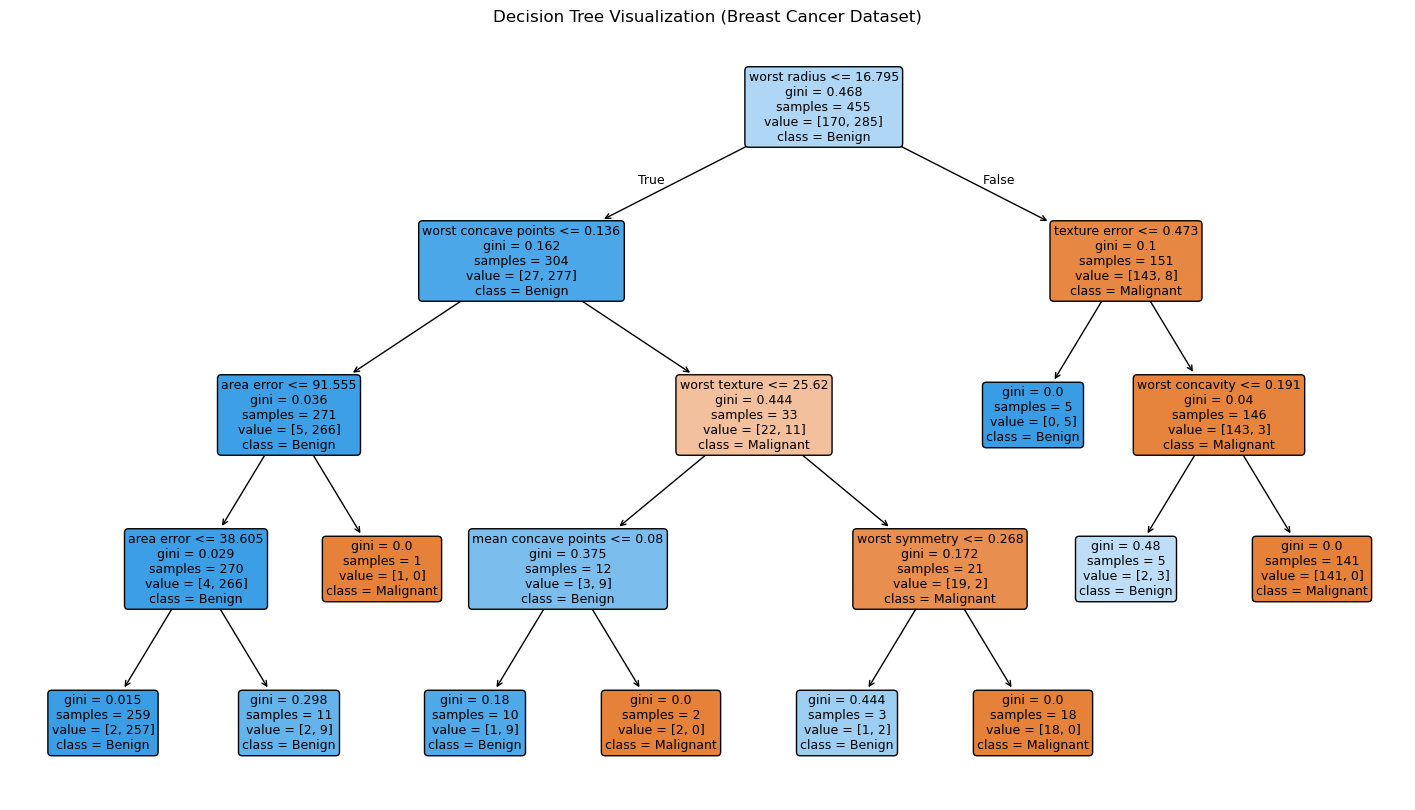

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

# 1. Load Built-in Dataset (No internet request needed)
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["Outcome"] = data.target

# 2. Train-Test Split
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Train Decision Tree Model
dt_classifier = DecisionTreeClassifier(
    criterion="gini", max_depth=4, min_samples_split=10, random_state=42
)
dt_classifier.fit(X_train, y_train)

# 4. Evaluation
y_pred = dt_classifier.predict(X_test)
print(f"Accuracy Score: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Classification Report:\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# 5. Visualization
plt.figure(figsize=(18, 10))
plot_tree(
    dt_classifier,
    feature_names=X.columns,
    class_names=["Malignant", "Benign"],
    filled=True,
    rounded=True,
    fontsize=9,
)
plt.title("Decision Tree Visualization (Breast Cancer Dataset)")
plt.savefig("decision_tree_structure.png", dpi=300, bbox_inches="tight")
plt.show()
